# Three car-like ORCA-MPPI routes in warehouse2

This restores the original three-car crossing scenario on the Bench-MR `warehouse2` map. The second route retains the published `testing_warehouse2` start and goal. Each car follows its own RRT-Connect anchor with bicycle-model steering. The pointed end and pale windshield show the **front**; the red bar shows the **rear**. A conservative circular collision envelope contains the drawn car body.

For the denser opposing-traffic stress case, see [`rrt_connect_warehouse2_car_like_traffic_jam.ipynb`](rrt_connect_warehouse2_car_like_traffic_jam.ipynb).

After a native-code update, rebuild with `cmake --build build/release --target mppi_all -j2`, restart the Jupyter kernel, and run all cells. A running kernel keeps an already-imported `mppi_ca_cpp` binary loaded.

![Three car-like warehouse agents](rrt_connect_warehouse2_car_like_multiagent.gif)


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from rrt_connect import RRTConnectPlanner
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())
world = suite['worlds']['warehouse2']


## Editable three-car tasks and geometry

Each start and goal is `[x, y, heading]`. The car body fits inside `ROBOT_RADIUS`, the radius used by RRT-Connect, ORCA, and obstacle checks. The car state includes signed speed and steering angle; MPPI samples jerk and steering rate.


In [2]:
SEED = 42
AGENT_NAMES = [
    'lower-left to upper-right',
    'testing_warehouse2',
    'middle-left to upper-right',
]
CUSTOM_STARTS = np.array([
    [7.5, -70.0,  0.50],
    [7.5, -10.0, -1.58],
    [7.5, -50.0,  0.00],
], dtype=float)
CUSTOM_GOALS = np.array([
    [116.0, -10.0,  0.50],
    [116.0, -70.0, -1.58],
    [116.0, -30.0,  0.00],
], dtype=float)

ROBOT_RADIUS = 0.70
CAR_LENGTH = 1.20
CAR_WIDTH = 0.65
WHEELBASE = 1.00
STEER_LIMIT = 0.60
STEER_RATE_LIMIT = 2.0
MAX_SPEED = 3.0
REVERSE_MAX_SPEED = 0.6
ACCEL_MAX = 1.5
BRAKE_MAX = 3.0
PLANNER_CLEARANCE = 0.15
JERK_MIN = -2.0
JERK_MAX = 2.0
DT = 0.1

if CUSTOM_STARTS.shape != CUSTOM_GOALS.shape or CUSTOM_STARTS.shape != (len(AGENT_NAMES), 3):
    raise ValueError('Provide one [x, y, heading] start and goal per car')
if not np.isfinite(CUSTOM_STARTS).all() or not np.isfinite(CUSTOM_GOALS).all():
    raise ValueError('Start and goal poses must be finite')
if np.hypot(CAR_LENGTH / 2, CAR_WIDTH / 2) > ROBOT_RADIUS:
    raise ValueError('The car body must fit inside the collision radius')
if WHEELBASE <= 0 or STEER_LIMIT <= 0 or STEER_LIMIT >= np.pi / 2:
    raise ValueError('Wheelbase and steering limit must define a finite turning radius')
reference_task = next(task for task in suite['tasks'] if task['id'] == 'testing_warehouse2')
assert np.allclose(CUSTOM_STARTS[1], reference_task['start'])
assert np.allclose(CUSTOM_GOALS[1], reference_task['goal'])
print(f'{len(AGENT_NAMES)} cars; max speed {MAX_SPEED:.1f}; acceleration {ACCEL_MAX:.1f}; '
      f'braking {BRAKE_MAX:.1f} map units/s²')


3 cars; max speed 3.0; acceleration 1.5; braking 3.0 map units/s²


## RRT-Connect anchors

Dotted paths are raw RRT-Connect results. Dashed paths are the collision-checked shortcut anchors passed to ORCA-MPPI. The starting cars show their initial headings.


In [3]:
planning_results = []
for agent_id, (start, goal) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS)):
    planner = RRTConnectPlanner(
        obstacles=world['obstacles'], bounds=world['bounds'],
        robot_radius=ROBOT_RADIUS, clearance=PLANNER_CLEARANCE,
        step_size=1.5, max_iterations=100_000, goal_sample_rate=0.05,
        smoothing_iterations=800, seed=SEED + agent_id,
    )
    result = planner.plan(start[:2], goal[:2])
    planning_results.append(result)
    length = sum(np.linalg.norm(np.subtract(b, a))
                 for a, b in zip(result.path, result.path[1:]))
    print(f'{AGENT_NAMES[agent_id]}: {result.iterations} RRT iterations, '
          f'{len(result.path)} anchor vertices, length {length:.1f}')
anchor_paths = [result.path for result in planning_results]


lower-left to upper-right: 266 RRT iterations, 10 anchor vertices, length 145.6
testing_warehouse2: 132 RRT iterations, 11 anchor vertices, length 137.6
middle-left to upper-right: 87 RRT iterations, 6 anchor vertices, length 120.4


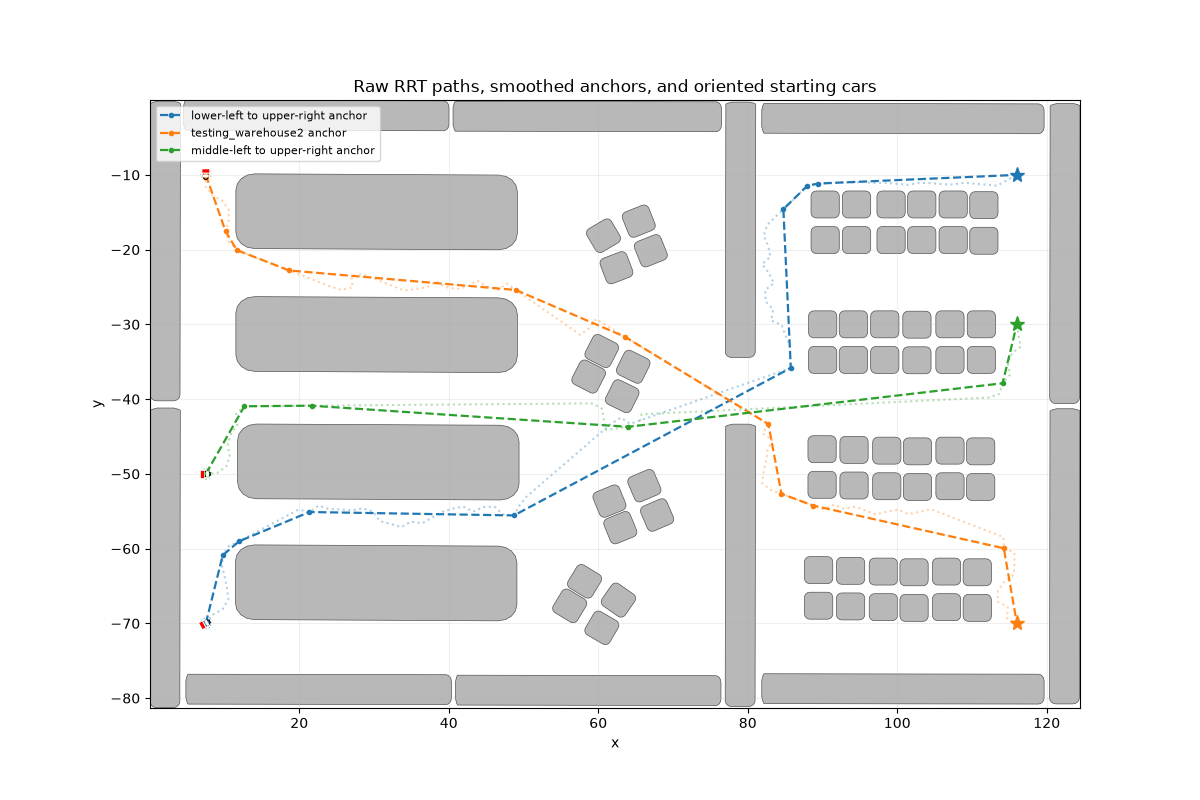

In [4]:
colors = plt.colormaps['tab10'](np.arange(len(AGENT_NAMES)))

def draw_world(ax):
    for vertices in world['obstacles']:
        ax.add_patch(PolygonPatch(vertices, closed=True, facecolor='0.72',
                                  edgecolor='0.32', linewidth=0.5))
    bounds = world['bounds']
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]),
           aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

def draw_car(ax, pose, color, alpha=1.0, safety_circle=False):
    """Draw a pointed front, pale windshield, and red rear at the car heading."""
    x, y, heading = pose[:3]
    rotation = np.array([[np.cos(heading), -np.sin(heading)],
                         [np.sin(heading),  np.cos(heading)]])
    def world_points(local):
        return np.asarray(local) @ rotation.T + [x, y]
    half_l, half_w = CAR_LENGTH / 2, CAR_WIDTH / 2
    body = world_points([[-half_l, -half_w], [0.30 * CAR_LENGTH, -half_w],
                         [half_l, -0.45 * half_w], [half_l, 0.45 * half_w],
                         [0.30 * CAR_LENGTH, half_w], [-half_l, half_w]])
    ax.add_patch(PolygonPatch(body, closed=True, facecolor=color,
                              edgecolor='black', linewidth=0.8, alpha=alpha, zorder=5))
    windshield = world_points([[0.12 * CAR_LENGTH, -0.65 * half_w],
                               [0.12 * CAR_LENGTH,  0.65 * half_w]])
    rear = world_points([[-0.88 * half_l, -0.75 * half_w],
                         [-0.88 * half_l,  0.75 * half_w]])
    ax.plot(windshield[:, 0], windshield[:, 1], color='white', linewidth=2.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='white', linewidth=4.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='red', linewidth=2.4,
            alpha=alpha, zorder=7)
    if safety_circle:
        ax.add_patch(Circle((x, y), ROBOT_RADIUS, fill=False, color=color,
                            linestyle=':', linewidth=0.8, alpha=0.65, zorder=4))

fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (start, goal, result) in enumerate(zip(CUSTOM_STARTS, CUSTOM_GOALS, planning_results)):
    raw, anchor = np.asarray(result.raw_path), np.asarray(result.path)
    color = colors[agent_id]
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.35)
    ax.plot(anchor[:, 0], anchor[:, 1], '--o', color=color, linewidth=1.6,
            markersize=3, label=f'{AGENT_NAMES[agent_id]} anchor')
    draw_car(ax, start, color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=11)
ax.set_title('Raw RRT paths, smoothed anchors, and oriented starting cars')
ax.legend(fontsize=8)
plt.show()


## Run concurrent car-like ORCA-MPPI inference

State is `[x, y, heading, velocity, steering angle, acceleration]`; controls are `[jerk, steering rate]`. `LONGITUDINAL_ACCEL_MIN/MAX` bound signed acceleration, `STEERING_RATE_MAX` bounds steering rate, and the existing `DIFF_DRIVE_V_MIN/MAX` and `DIFF_DRIVE_W_MIN/MAX` bound velocity and steering angle. Every rollout integrates `a[k+1] = a[k] + j[k] * DT`, `v[k+1] = v[k] + a[k] * DT`, and `steering[k+1] = steering[k] + steering_rate[k] * DT`. `LONGITUDINAL_JERK_MIN/MAX` bound jerk at ±2 units/s³. Speed-limit headroom ensures acceleration can return to zero before saturation, including beyond the horizon. The first control of a new horizon uses the measured velocity, acceleration, and steering angle. Reverse is capped at 0.6 units/s; direction changes pass continuously through zero speed. The controller uses the circular collision envelope.

Success requires all three cars to be within 3.0 map units of their goal positions at the same step; goal heading is displayed but is not a stopping criterion.

ORCA also reserves each moving car's jerk-limited stopping arc length plus one simulation step of travel as extra clearance. The drawn body and reported physical gaps still use `ROBOT_RADIUS`.

Quadratic jerk and steering-rate costs use the physically bounded rollout controls. Sampling standard deviations are 0.5 map units/s³ and 0.2 rad/s, below the unchanged hard limits of ±2.

Temporal costs `500 * sum((Δjerk)²)` and `1000 * sum((Δsteering_rate)²)` discourage alternating commands inside each rollout. The first change is measured from the previous executed command, including across horizons. These are soft costs, not another state or derivative limit.

The three-car run allows 65 simulated seconds, giving the gentler command transitions time to finish the same routes.


In [5]:
AGENTS_NUM = len(AGENT_NAMES)
start_states = np.c_[CUSTOM_STARTS, np.zeros((AGENTS_NUM, 3))]
goal_states = np.c_[CUSTOM_GOALS, np.zeros((AGENTS_NUM, 3))]
agent_params = {
    AGENT_SIZE: ROBOT_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: MAX_SPEED, DIFF_DRIVE_V_MIN: -REVERSE_MAX_SPEED,
    LONGITUDINAL_ACCEL_MIN: -BRAKE_MAX, LONGITUDINAL_ACCEL_MAX: ACCEL_MAX,
    LONGITUDINAL_JERK_MIN: JERK_MIN, LONGITUDINAL_JERK_MAX: JERK_MAX,
    DIFF_DRIVE_W_MAX: STEER_LIMIT, DIFF_DRIVE_W_MIN: -STEER_LIMIT,
    STEERING_RATE_MAX: STEER_RATE_LIMIT,
}
agents_params = [agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.CarLikeDyn(WHEELBASE) for _ in range(AGENTS_NUM)]
alg_params = {
    SAMPLE_BATCH_SIZE: 160, SAMPLE_TIME_STEPS: 15, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    # Variances of [jerk, steering_rate]; standard deviations are 0.5 and 0.2.
    CONTROL_COV: np.diag([0.25, 0.04]),
    JERK_COST_WEIGHT: 100.0, STEERING_RATE_COST_WEIGHT: 300.0,
    JERK_CHANGE_COST_WEIGHT: 500.0, STEERING_RATE_CHANGE_COST_WEIGHT: 1000.0,
    RUNNING_COST_WEIGH: 300.0, TERMINAL_WEIGHT: 2000.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 1200.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 4.0, USE_CAR_LIKE_DYN: True,
    DIST_BETWEEN_AXLES: WHEELBASE,
    K_ALPHA: -2.96, RAD_EPS: 0.05, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 1.0,
    ORCA_RESPONSIBILITY_FACTOR: 0.5, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.7, ANCHOR_PATH_WEIGHT: 2000.0,
    ANCHOR_HEADING_WEIGHT: 500.0, CONTROL_SMOOTHNESS_WEIGHT: 20.0,
}
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: 3.0, MAX_EXP_STEPS: 650}
expanded_bounds = np.asarray(world['bounds']) + np.array([-1, -1, 1, 1]) * (ROBOT_RADIUS + 0.05)
controller_obstacles = world['obstacles'] + boundary_obstacles(expanded_bounds)
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths,
)
states = np.asarray(log_state)
xy = states[:, :, :2]
goal_errors = np.linalg.norm(xy[-1] - goal_states[:, :2], axis=1)
# Velocity and steering are physical state, not commanded pose increments.
speeds = states[1:, :, 3]
previous_speeds = states[:-1, :, 3]
accelerations = states[:, :, 5]
speed_rates = np.diff(states[:, :, 3], axis=0) / DT
np.testing.assert_allclose(speed_rates, accelerations[:-1], atol=1e-8)
steering_rates = np.diff(states[:, :, 4], axis=0) / DT
jerks = np.diff(accelerations, axis=0) / DT
# Raw differences measure chatter; they are diagnostics, not extra controls.
control_values = np.stack([jerks, steering_rates], axis=-1)
control_rms = np.sqrt(np.mean(control_values**2, axis=(0, 1)))
control_change_rms = np.sqrt(np.mean(np.diff(control_values, axis=0)**2, axis=(0, 1)))
print('RMS [jerk, steering_rate]:', np.round(control_rms, 4))
print('RMS successive-command changes:', np.round(control_change_rms, 4))
print(f'jerk near hard bounds: {np.mean((jerks <= 0.95 * JERK_MIN) | (jerks >= 0.95 * JERK_MAX)):.1%}')
max_acceleration = float(accelerations.max())
max_braking = float(-accelerations.min())
assert np.max(states[:, :, 3]) <= MAX_SPEED + 1e-6
assert np.min(states[:, :, 3]) >= -REVERSE_MAX_SPEED - 1e-6
assert accelerations.max() <= ACCEL_MAX + 1e-6
assert accelerations.min() >= -BRAKE_MAX - 1e-6
assert jerks.min() >= JERK_MIN - 1e-6
assert jerks.max() <= JERK_MAX + 1e-6
assert np.max(np.abs(states[:, :, 4])) <= STEER_LIMIT + 1e-6
assert np.max(np.abs(steering_rates)) <= STEER_RATE_LIMIT + 1e-6

reverse_steps = np.sum(speeds < -0.05, axis=0)
forward_after_reverse = []
for agent_id, name in enumerate(AGENT_NAMES):
    reverse_indices = np.flatnonzero(speeds[:, agent_id] < -0.05)
    if len(reverse_indices) and np.any(speeds[reverse_indices[-1] + 1:, agent_id] > 0.05):
        forward_after_reverse.append(name)
print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
print(f'measured a range=[{-max_braking:.2f}, {max_acceleration:.2f}] units/s²; '
      f'max steering rate={np.max(np.abs(steering_rates)):.2f} rad/s')
print(f'measured jerk range=[{jerks.min():.2f}, {jerks.max():.2f}] units/s³; '
      f'max acceleration step={np.max(np.abs(np.diff(accelerations, axis=0))):.3f}')
print(f'reverse steps by car: {dict(zip(AGENT_NAMES, reverse_steps.tolist()))}')
print(f'reversed then moved forward: {forward_after_reverse}')
for name, error in zip(AGENT_NAMES, goal_errors):
    print(f'{name}: final XY error={error:.2f}')
closest = (np.inf, None, None, None)
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        distances = np.linalg.norm(xy[:, first] - xy[:, second], axis=1)
        step = int(np.argmin(distances))
        gap = float(distances[step] - 2 * ROBOT_RADIUS)
        if gap < closest[0]:
            closest = (gap, first, second, step)
print(f'closest circular-envelope gap={closest[0]:.3f} '
      f'({AGENT_NAMES[closest[1]]}/{AGENT_NAMES[closest[2]]}, step {closest[3]})')

assert success, "Three-car run must reach all XY goals within the configured time budget"


RMS [jerk, steering_rate]: [0.6485 0.3233]
RMS successive-command changes: [0.5449 0.3391]
jerk near hard bounds: 1.3%
success=True, collisions=0.0, steps=618, wall time=110.34s
measured a range=[-1.84, 1.47] units/s²; max steering rate=1.37 rad/s
measured jerk range=[-2.00, 2.00] units/s³; max acceleration step=0.200
reverse steps by car: {'lower-left to upper-right': 0, 'testing_warehouse2': 12, 'middle-left to upper-right': 0}
reversed then moved forward: []
lower-left to upper-right: final XY error=2.99
testing_warehouse2: final XY error=1.12
middle-left to upper-right: final XY error=1.74
closest circular-envelope gap=1.589 (lower-left to upper-right/testing_warehouse2, step 347)


## Executed paths, car orientation, and speed

Solid lines show actual trajectories. The final body poses retain simulated headings; the close-ups mark the white front and red rear. The raw state and control plots show velocity, signed acceleration, jerk, and steering angle; dashed lines are physical limits. The animation follows the first car while the full map stays visible.


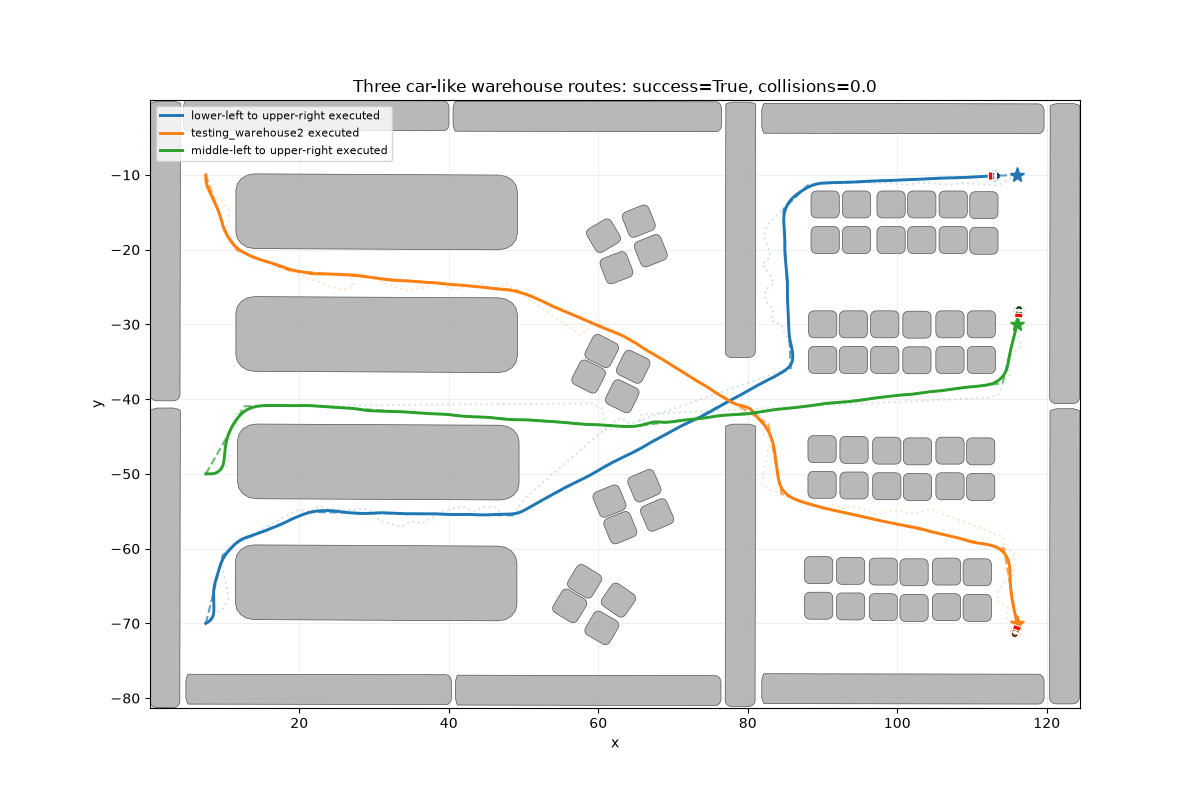

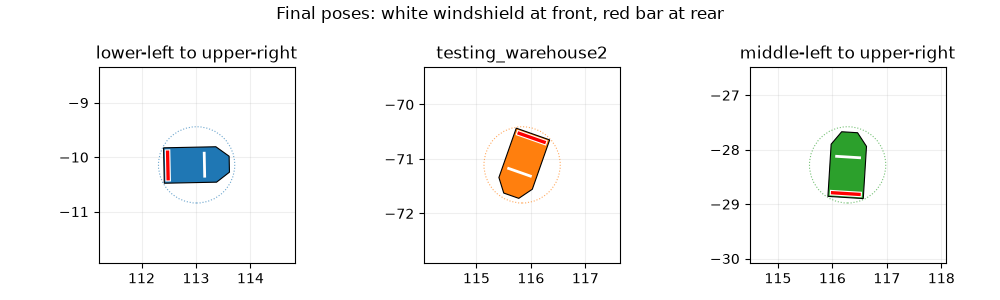

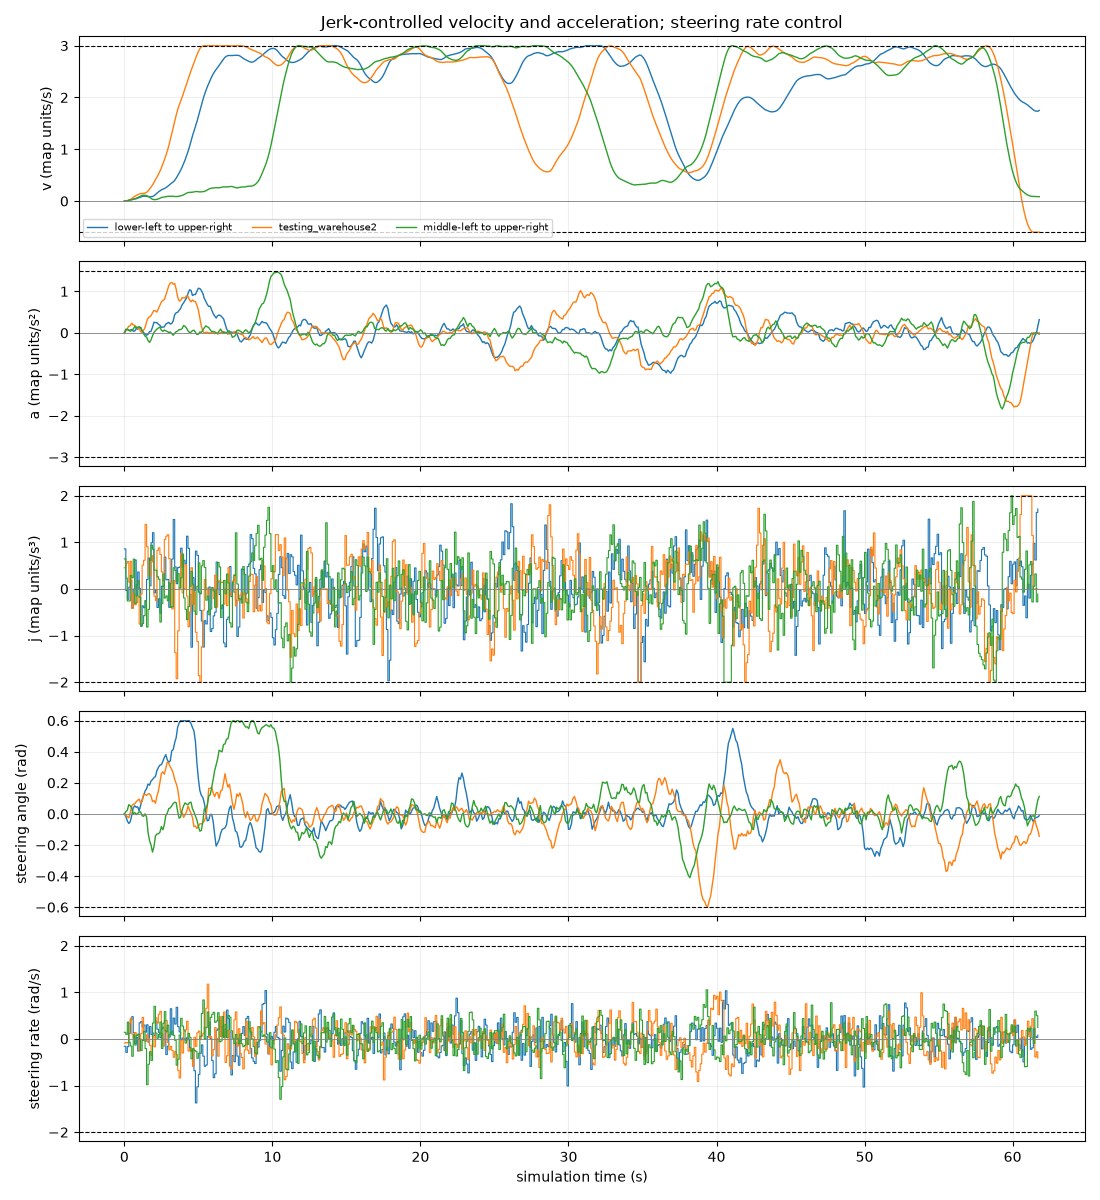

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (goal, result) in enumerate(zip(CUSTOM_GOALS, planning_results)):
    color = colors[agent_id]
    raw, anchor = np.asarray(result.raw_path), np.asarray(result.path)
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.2)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.7)
    ax.plot(xy[:, agent_id, 0], xy[:, agent_id, 1], color=color,
            linewidth=2.1, label=f'{AGENT_NAMES[agent_id]} executed')
    draw_car(ax, states[-1, agent_id], color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=11)
ax.set_title(f'Three car-like warehouse routes: success={success}, collisions={collisions}')
ax.legend(fontsize=8)
plt.show()

fig, close_axes = plt.subplots(1, AGENTS_NUM, figsize=(10, 3))
for agent_id, ax_close in enumerate(close_axes):
    final_pose = states[-1, agent_id]
    draw_car(ax_close, final_pose, colors[agent_id], safety_circle=True)
    ax_close.set(xlim=(final_pose[0] - 1.8, final_pose[0] + 1.8),
                 ylim=(final_pose[1] - 1.8, final_pose[1] + 1.8),
                 aspect='equal', title=AGENT_NAMES[agent_id])
    ax_close.grid(alpha=0.2)
fig.suptitle('Final poses: white windshield at front, red bar at rear')
fig.tight_layout()
plt.show()

# Raw state/control differences: no smoothing or moving averages.
fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
state_times = np.arange(len(states)) * DT
control_times = state_times[:-1]
for agent_id, agent_name in enumerate(AGENT_NAMES):
    color = colors[agent_id]
    axes[0].plot(state_times, states[:, agent_id, 3], color=color, label=agent_name, linewidth=1)
    axes[1].plot(state_times, accelerations[:, agent_id], color=color, linewidth=1)
    axes[2].step(control_times, jerks[:, agent_id], where='post', color=color, linewidth=0.8)
    axes[3].plot(state_times, states[:, agent_id, 4], color=color, linewidth=1)
    axes[4].step(control_times, steering_rates[:, agent_id], where='post', color=color, linewidth=0.8)
axes[0].axhline(MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].axhline(-REVERSE_MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].set(ylabel='v (map units/s)', title='Jerk-controlled velocity and acceleration; steering rate control')
axes[0].legend(fontsize=7, ncol=3)
axes[1].axhline(ACCEL_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].axhline(-BRAKE_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].set(ylabel='a (map units/s²)')
axes[2].axhline(JERK_MAX, color='black', linestyle='--', linewidth=0.8)
axes[2].axhline(JERK_MIN, color='black', linestyle='--', linewidth=0.8)
axes[2].set(ylabel='j (map units/s³)')
axes[3].axhline(STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].axhline(-STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].set(ylabel='steering angle (rad)')
axes[4].axhline(STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].axhline(-STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].set(ylabel='steering rate (rad/s)', xlabel='simulation time (s)')
for ax in axes:
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.grid(alpha=0.2)
fig.tight_layout()
DYNAMICS_PLOT_PATH = ROOT / 'benchmarks/rrt_connect_warehouse2_car_like_multiagent_dynamics.png'
fig.savefig(DYNAMICS_PLOT_PATH, dpi=160)
plt.show()


In [7]:
fig, (ax_map, ax_close) = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.7, 1]}
)
frame_indices = np.unique(np.linspace(0, len(states) - 1, min(120, len(states))).astype(int))
FOLLOW_AGENT = 0

def animate(frame_number):
    state_index = int(frame_indices[frame_number])
    ax_map.clear()
    ax_close.clear()
    draw_world(ax_map)
    draw_world(ax_close)
    follow_pose = states[state_index, FOLLOW_AGENT]
    ax_close.set(xlim=(follow_pose[0] - 4, follow_pose[0] + 4),
                 ylim=(follow_pose[1] - 3.5, follow_pose[1] + 3.5))
    for agent_id, (goal, anchor_path) in enumerate(zip(CUSTOM_GOALS, anchor_paths)):
        color = colors[agent_id]
        anchor = np.asarray(anchor_path)
        for ax in (ax_map, ax_close):
            ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color,
                    alpha=0.65, linewidth=1.4)
            ax.plot(xy[:state_index + 1, agent_id, 0],
                    xy[:state_index + 1, agent_id, 1],
                    color=color, linewidth=2)
            draw_car(ax, states[state_index, agent_id], color, safety_circle=True)
            ax.plot(*goal[:2], '*', color=color, markersize=11)
    ax_map.set_title(f'Three car-like routes: step {state_index}/{len(states) - 1}')
    ax_close.set_title(f'Following {AGENT_NAMES[FOLLOW_AGENT]}: white front, red rear')

animation = FuncAnimation(fig, animate, frames=len(frame_indices), interval=100)
GIF_PATH = ROOT / 'benchmarks/rrt_connect_warehouse2_car_like_multiagent.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))


<IPython.core.display.Image object>


## Reverse, stop, and drive forward

This separate maneuver demonstrates the signed bicycle-model speed on the same warehouse map. The car backs from x=75 to x=71 at at most 0.6 units/s, passes smoothly through zero speed before changing direction, then follows a new RRT-Connect anchor toward x=90 at up to 2.0 units/s. The full measured velocity, acceleration, and steering state carry over through the waypoint change. The route switch is a task instruction; reverse motion and the gear transition are handled by the controller.


In [8]:
import mppi_ca_cpp as mppi

reverse_start = np.array([75.0, -41.5, 0.0, 0.0, 0.0, 0.0])
reverse_goal = np.array([71.0, -41.5, 0.0])
forward_goal = np.array([90.0, -41.5, 0.0])
reverse_planner = RRTConnectPlanner(
    obstacles=world['obstacles'], bounds=world['bounds'],
    robot_radius=ROBOT_RADIUS, clearance=PLANNER_CLEARANCE,
    step_size=1.5, smoothing_iterations=800, seed=42,
)
assert all(reverse_planner.point_is_free(point[:2])
           for point in (reverse_start, reverse_goal, forward_goal))
assert reverse_planner.segment_is_free(reverse_start[:2], reverse_goal[:2])
reverse_anchor = [reverse_start[:2].tolist(), reverse_goal[:2].tolist()]
forward_anchor = reverse_planner.plan(reverse_goal[:2], forward_goal[:2]).path

reverse_agent_params = agent_params | {
    DIFF_DRIVE_V_MAX: 2.0, LONGITUDINAL_ACCEL_MIN: -4.0, LONGITUDINAL_ACCEL_MAX: 1.0,
}
reverse_alg_params = alg_params | {
    MA_COST_EN: False,  # Inherit the regularized costs and sampling covariance.
    TERMINAL_LOOKAHEAD_DISTANCE: 2.0,
}
reverse_controller = mppi.Controller()
reverse_controller.set_agent_params(mppi.convert_agent_params(reverse_agent_params))
reverse_controller.set_alg_params(mppi.convert_alg_params(reverse_alg_params))
reverse_controller.set_obstacles(controller_obstacles)
reverse_controller.set_anchor_path(reverse_anchor)
mppi.set_random_seed(23)
reverse_model = dyn_models.CarLikeDyn(WHEELBASE)
reverse_model.configure_limits(reverse_agent_params)
reverse_states = [reverse_start.copy()]
reverse_controls = []
reverse_phase = 'reverse'
switch_step = None
for step in range(300):
    current = reverse_states[-1]
    target = reverse_goal if reverse_phase == 'reverse' else forward_goal
    control, _ = reverse_controller.next_step(
        current, np.empty((0, 4)), np.empty(0), target)
    following = current.copy()
    following = (reverse_model.state_shift(current, DT)
                 + reverse_model.dynamic_model(current, control, DT))
    reverse_states.append(following)
    reverse_controls.append(control.copy())
    if reverse_phase == 'reverse' and np.linalg.norm(following[:2] - reverse_goal[:2]) < 0.6:
        reverse_phase = 'forward'
        switch_step = step + 1
        reverse_controller.set_anchor_path(forward_anchor)
    if reverse_phase == 'forward' and np.linalg.norm(following[:2] - forward_goal[:2]) < 1.0:
        break
reverse_states = np.asarray(reverse_states)
reverse_controls = np.asarray(reverse_controls)
reverse_speeds = reverse_states[1:, 3]
reverse_accelerations = reverse_states[:, 5]
reverse_jerks = reverse_controls[:, 0]
np.testing.assert_allclose(np.diff(reverse_accelerations) / DT, reverse_jerks, atol=1e-8)
assert reverse_jerks.min() >= JERK_MIN - 1e-8
assert reverse_jerks.max() <= JERK_MAX + 1e-8
np.testing.assert_allclose(np.diff(reverse_states[:, 3]) / DT, reverse_accelerations[:-1], atol=1e-8)
assert reverse_accelerations.min() >= -4.0 - 1e-8
assert reverse_accelerations.max() <= 1.0 + 1e-8
assert np.max(np.abs(np.diff(reverse_states[:, 4]) / DT)) <= STEER_RATE_LIMIT + 1e-8
assert switch_step is not None
assert np.any(reverse_speeds[:switch_step] < -0.05)
assert np.any(reverse_speeds[switch_step:] > 0.05)
assert np.max(-reverse_speeds) <= REVERSE_MAX_SPEED + 1e-6
assert np.max(reverse_speeds) <= 2.0 + 1e-6
assert np.linalg.norm(reverse_states[-1, :2] - forward_goal[:2]) < 1.0
print(f'Reversed for {np.sum(reverse_speeds < -0.05)} steps, changed task at step {switch_step}, '
      f'then drove forward for {np.sum(reverse_speeds[switch_step:] > 0.05)} steps.')
print(f'Peak reverse={max(0.0, -reverse_speeds.min()):.2f}, '
      f'peak forward={reverse_speeds.max():.2f} units/s; '
      f'final goal error={np.linalg.norm(reverse_states[-1, :2] - forward_goal[:2]):.2f}.')


Reversed for 79 steps, changed task at step 72, then drove forward for 126 steps.
Peak reverse=0.60, peak forward=1.89 units/s; final goal error=0.87.


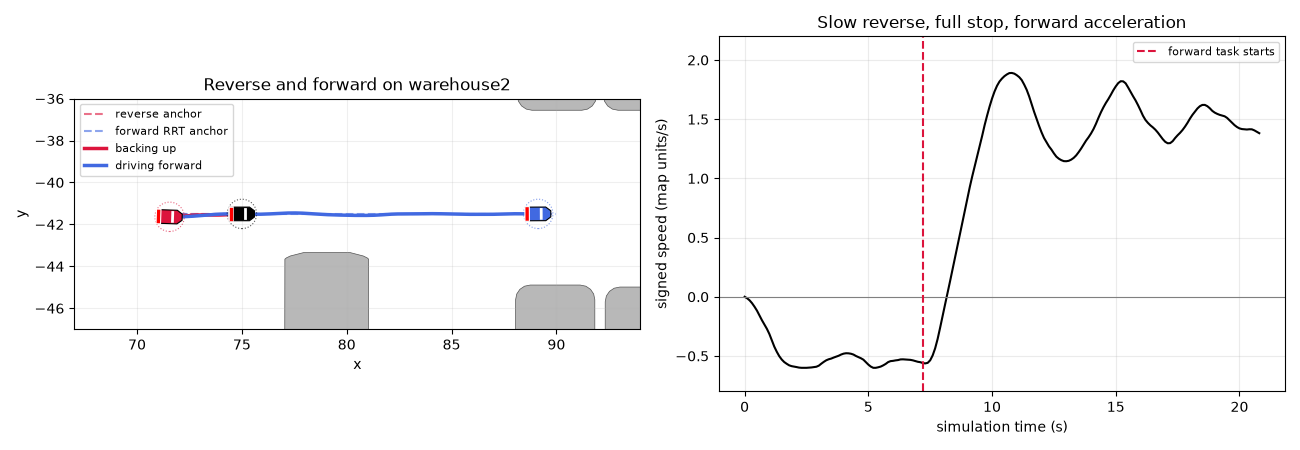

In [9]:
fig, (ax_route, ax_speed) = plt.subplots(1, 2, figsize=(13, 4.5))
draw_world(ax_route)
ax_route.set(xlim=(67, 94), ylim=(-47, -36), title='Reverse and forward on warehouse2')
ax_route.plot(*np.asarray(reverse_anchor).T, '--', color='crimson', alpha=0.6, label='reverse anchor')
ax_route.plot(*np.asarray(forward_anchor).T, '--', color='royalblue', alpha=0.6, label='forward RRT anchor')
ax_route.plot(reverse_states[:switch_step + 1, 0], reverse_states[:switch_step + 1, 1],
              color='crimson', linewidth=2.5, label='backing up')
ax_route.plot(reverse_states[switch_step:, 0], reverse_states[switch_step:, 1],
              color='royalblue', linewidth=2.5, label='driving forward')
for pose, color in ((reverse_states[0], 'black'),
                    (reverse_states[switch_step], 'crimson'),
                    (reverse_states[-1], 'royalblue')):
    draw_car(ax_route, pose, color, safety_circle=True)
ax_route.legend(fontsize=8)
ax_speed.plot(np.arange(len(reverse_speeds)) * DT, reverse_speeds, color='black')
ax_speed.axhline(0, color='gray', linewidth=0.8)
ax_speed.axvline(switch_step * DT, color='crimson', linestyle='--', label='forward task starts')
ax_speed.set(xlabel='simulation time (s)', ylabel='signed speed (map units/s)',
             title='Slow reverse, full stop, forward acceleration', ylim=(-0.8, 2.2))
ax_speed.grid(alpha=0.25)
ax_speed.legend(fontsize=8)
fig.tight_layout()
plt.show()


Acceleration, velocity, and steering angle are integrated from the current six-state vehicle model. Hard jerk and steering-rate limits still apply inside every rollout. Quadratic costs of `100 * sum(j²)` and `300 * sum(steering_rate²)`, with sampling variances `[0.25, 0.04]`, penalize control effort. Additional costs of `500 * sum((Δjerk)²)` and `1000 * sum((Δsteering_rate)²)` penalize command changes, including at horizon boundaries. The plots show raw state and control traces without filters.


## Seeded comparison of raw controls

A two-bend anchor in free space isolates the control costs and sampling changes. Both runs use the same native dynamics, physical limits, 26-second duration, and seed. The previous magnitude-only configuration uses variances `[0.5625, 0.04]`, jerk/steering-rate weights `100/300`, and zero command-change weights. The new configuration keeps the magnitude costs, adds command-change weights `500/1000`, and uses variances `[0.25, 0.04]`. Steering noise stays at 0.2 rad/s (10% of its hard bound), preserving exploration of tight starting turns; jerk noise falls from 0.75 to 0.5. RMS successive-command differences measure high-frequency chatter, and goal error checks progress. No trace is filtered.


Previous {"rms_control": [0.8911457528481707, 0.4143737481728522], "rms_command_change": [1.029954726729008, 0.6111826289377322], "jerk_saturation_fraction": 0.05384615384615385, "goal_error": 0.5026807851822477, "jerk_cost_weight": 100.0, "steering_rate_cost_weight": 300.0, "jerk_change_cost_weight": 0.0, "steering_rate_change_cost_weight": 0.0, "sampling_variances": [0.5625, 0.04]}
Temporal {"rms_control": [0.744267759816004, 0.31879578755004473], "rms_command_change": [0.5435632459620463, 0.3251950463352587], "jerk_saturation_fraction": 0.03461538461538462, "goal_error": 1.5664081396398104, "jerk_cost_weight": 100.0, "steering_rate_cost_weight": 300.0, "jerk_change_cost_weight": 500.0, "steering_rate_change_cost_weight": 1000.0, "sampling_variances": [0.25, 0.04]}
Reduction in RMS command changes [jerk, steering_rate]: [47.2 46.8] %


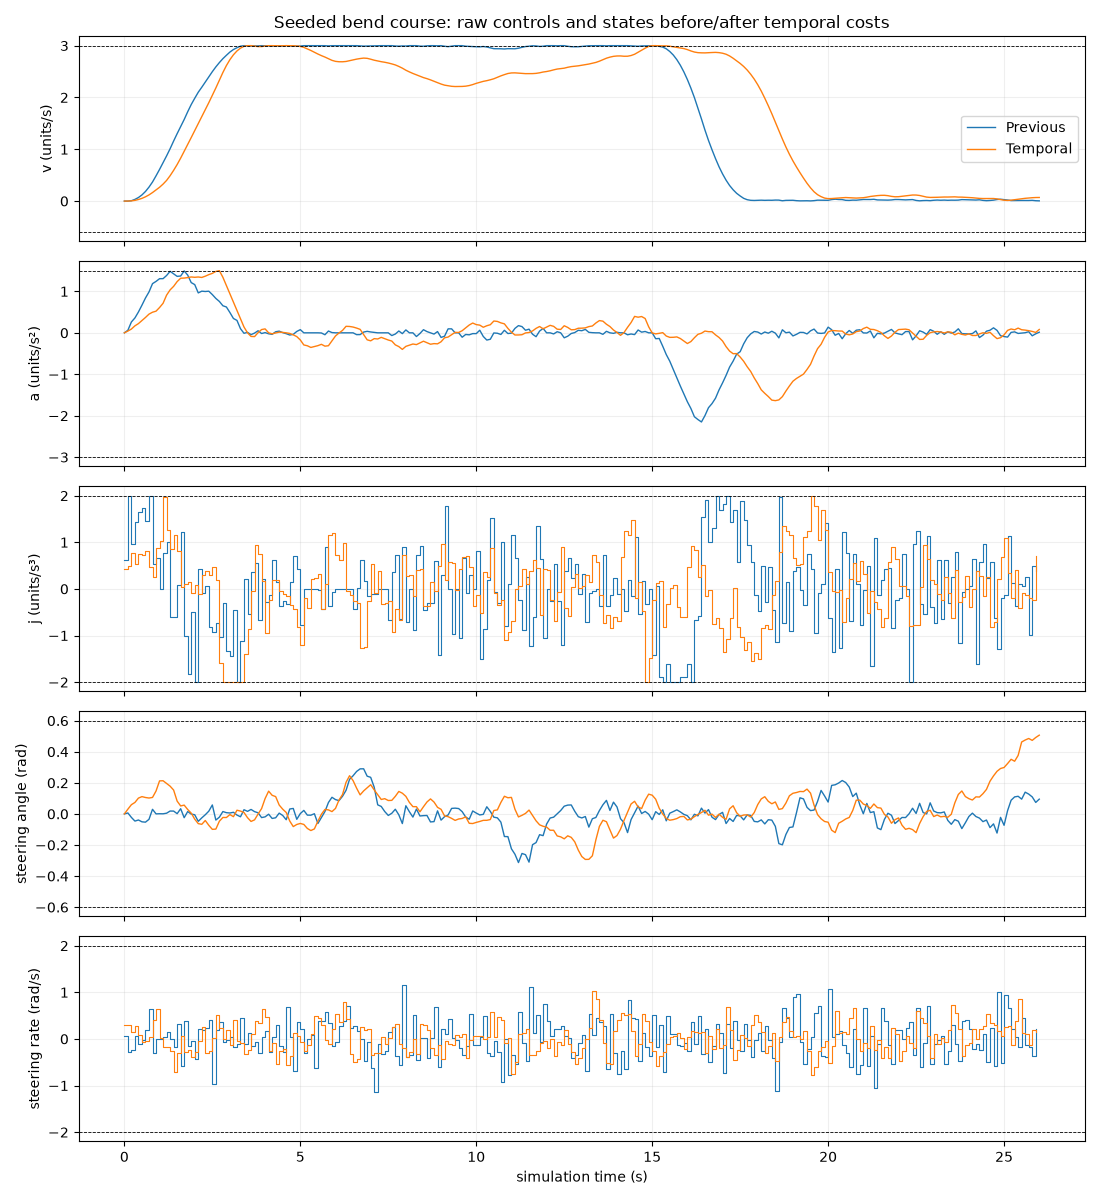

In [10]:
# Same native dynamics, anchor, physical limits and seed in both runs.
# Free space isolates the effect of regularization from obstacle/ORCA decisions.
comparison_anchor = [(0.0, 0.0), (15.0, 0.0), (25.0, 10.0), (40.0, 10.0)]
comparison_goal = np.array([40.0, 10.0, 0.0])
comparison_runs = {}
for label, settings in {
    'Previous': {JERK_COST_WEIGHT: 100.0, STEERING_RATE_COST_WEIGHT: 300.0,
                 JERK_CHANGE_COST_WEIGHT: 0.0, STEERING_RATE_CHANGE_COST_WEIGHT: 0.0,
                 CONTROL_COV: np.diag([0.5625, 0.04])},
    'Temporal': {},
}.items():
    params = alg_params | {MA_COST_EN: False} | settings
    controller = mppi.Controller()
    controller.set_agent_params(mppi.convert_agent_params(agent_params))
    controller.set_alg_params(mppi.convert_alg_params(params))
    controller.set_anchor_path(comparison_anchor)
    mppi.set_random_seed(23)
    model = dyn_models.CarLikeDyn(WHEELBASE)
    model.configure_limits(agent_params)
    trace = [np.zeros(6)]
    commands = []
    for _ in range(260):
        command, rollouts = controller.next_step(
            trace[-1], np.empty((0, 4)), np.empty(0), comparison_goal)
        following = model.state_shift(trace[-1], DT) + model.dynamic_model(trace[-1], command, DT)
        np.testing.assert_allclose((following[[5, 4]] - trace[-1][[5, 4]]) / DT,
                                   command, atol=1e-8)
        trace.append(following)
        commands.append(command.copy())
    trace, commands = np.asarray(trace), np.asarray(commands)
    np.testing.assert_allclose(np.diff(trace[:, 3]) / DT, trace[:-1, 5], atol=1e-8)
    assert trace[:, 3].min() >= -REVERSE_MAX_SPEED - 1e-8
    assert trace[:, 3].max() <= MAX_SPEED + 1e-8
    assert trace[:, 5].min() >= -BRAKE_MAX - 1e-8
    assert trace[:, 5].max() <= ACCEL_MAX + 1e-8
    assert commands[:, 0].min() >= JERK_MIN - 1e-8
    assert commands[:, 0].max() <= JERK_MAX + 1e-8
    assert abs(commands[:, 1]).max() <= STEER_RATE_LIMIT + 1e-8
    assert abs(trace[:, 4]).max() <= STEER_LIMIT + 1e-8
    metrics = {
        'rms_control': np.sqrt(np.mean(commands**2, axis=0)).tolist(),
        'rms_command_change': np.sqrt(np.mean(np.diff(commands, axis=0)**2, axis=0)).tolist(),
        'jerk_saturation_fraction': float(np.mean(abs(commands[:, 0]) >= 0.95 * JERK_MAX)),
        'goal_error': float(np.linalg.norm(trace[-1, :2] - comparison_goal[:2])),
        'jerk_cost_weight': params[JERK_COST_WEIGHT],
        'steering_rate_cost_weight': params[STEERING_RATE_COST_WEIGHT],
        'jerk_change_cost_weight': params[JERK_CHANGE_COST_WEIGHT],
        'steering_rate_change_cost_weight': params[STEERING_RATE_CHANGE_COST_WEIGHT],
        'sampling_variances': np.diag(params[CONTROL_COV]).tolist(),
    }
    assert metrics['goal_error'] < 3.0
    comparison_runs[label] = {'states': trace, 'controls': commands, 'metrics': metrics}
    print(label, json.dumps(metrics))
original = np.asarray(comparison_runs['Previous']['metrics']['rms_command_change'])
regularized = np.asarray(comparison_runs['Temporal']['metrics']['rms_command_change'])
print('Reduction in RMS command changes [jerk, steering_rate]:',
      np.round(100 * (1 - regularized / original), 1), '%')

fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
for label, result in comparison_runs.items():
    trace, commands = result['states'], result['controls']
    t = np.arange(len(trace)) * DT
    axes[0].plot(t, trace[:, 3], label=label, linewidth=1)
    axes[1].plot(t, trace[:, 5], linewidth=1)
    axes[2].step(t[:-1], commands[:, 0], where='post', linewidth=0.8)
    axes[3].plot(t, trace[:, 4], linewidth=1)
    axes[4].step(t[:-1], commands[:, 1], where='post', linewidth=0.8)
for ax, label, bounds in zip(axes, ['v (units/s)', 'a (units/s²)', 'j (units/s³)',
                                  'steering angle (rad)', 'steering rate (rad/s)'],
                            [(-REVERSE_MAX_SPEED, MAX_SPEED), (-BRAKE_MAX, ACCEL_MAX),
                             (JERK_MIN, JERK_MAX), (-STEER_LIMIT, STEER_LIMIT),
                             (-STEER_RATE_LIMIT, STEER_RATE_LIMIT)]):
    ax.set_ylabel(label)
    for bound in bounds:
        ax.axhline(bound, color='black', linestyle='--', linewidth=0.6)
    ax.grid(alpha=0.2)
axes[0].set_title('Seeded bend course: raw controls and states before/after temporal costs')
axes[0].legend()
axes[-1].set_xlabel('simulation time (s)')
fig.tight_layout()
fig.savefig(ROOT / 'benchmarks/car_control_regularization_comparison.png', dpi=160)
(ROOT / 'benchmarks/car_control_regularization_metrics.json').write_text(
    json.dumps({label: run['metrics'] for label, run in comparison_runs.items()}, indent=2) + '\n')
plt.show()
